<a href="https://colab.research.google.com/github/MedA-G/Machine-Learning/blob/main/PAProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importing the Dependencies

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

1-Exploratory Data Analysis (EDA)

Data Collection and Data Processing

In [ ]:
#loading the dataset to a pandas Dataframe
# We use on_bad_lines='skip' and engine='python' to handle mismatched quotes / EOF errors near row 79952
E_Commerce = pd.read_csv('/content/Amazon Sale Report.csv', on_bad_lines='skip', engine='python')
E_Commerce

,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79946,79946,403-2439603-8859565,05-07-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3504,JNE3504-KR-XXL,kurta,...,INR,431.00,BENGALURU,KARNATAKA,560064.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,False
79947,79947,406-7156805-9445910,05-07-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,SET394,SET394-KR-NP-XS,Set,...,INR,1073.00,IDAR,Gujarat,383430.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,False
79948,79948,402-6895993-7806705,05-07-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,SET282,SET282-KR-PP-M,Set,...,INR,1043.00,MARUDUR,TAMIL NADU,639107.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,False
79949,79949,405-6416810-2099547,05-07-22,Shipped,Amazon,Amazon.in,Expedited,SET110,SET110-KR-PP-M,Set,...,INR,837.00,HYDERABAD,TELANGANA,500081.0,IN,NaN,False,NaN,False


In [ ]:
E_Commerce.head()

,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN


In [ ]:
# number of rows and columns
E_Commerce.shape

(79951, 24)

In [ ]:
E_Commerce.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79951 entries, 0 to 79950
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   index               79951 non-null  int64  
 1   Order ID            79951 non-null  object 
 2   Date                79951 non-null  object 
 3   Status              79951 non-null  object 
 4   Fulfilment          79951 non-null  object 
 5   Sales Channel       79951 non-null  object 
 6   ship-service-level  79951 non-null  object 
 7   Style               79951 non-null  object 
 8   SKU                 79951 non-null  object 
 9   Category            79951 non-null  object 
 10  Size                79951 non-null  object 
 11  ASIN                79951 non-null  object 
 12  Courier Status      75276 non-null  object 
 13  Qty                 79951 non-null  int64  
 14  currency            75194 non-null  object 
 15  Amount              75194 non-null  float64
 16  ship

In [ ]:
E_Commerce.describe()  #describe --> statistical measures of the data

,index,Qty,Amount,ship-postal-code
count,79951.000000,79951.000000,75194.000000,79931.000000
mean,39975.000000,0.901815,643.841968,462927.279041
std,23080.010023,0.320905,278.706365,193380.970221
min,0.000000,0.000000,0.000000,110001.000000
25%,19987.500000,1.000000,448.570000,380051.500000
50%,39975.000000,1.000000,599.000000,500025.000000
75%,59962.500000,1.000000,788.000000,600032.000000
max,79950.000000,15.000000,5584.000000,989898.000000


Missing Values Duplicates

In [ ]:
missing = pd.DataFrame({
    "missing_count": E_Commerce.isnull().sum(),
    "missing_pct": (E_Commerce.isnull().mean() * 100).round(2)
}).sort_values("missing_pct", ascending=False)

display(missing)

print("Duplicate rows:", E_Commerce.duplicated().sum())

,missing_count,missing_pct
fulfilled-by,53331,66.70
Unnamed: 22,49050,61.35
promotion-ids,29478,36.87
currency,4757,5.95
Amount,4757,5.95
Courier Status,4675,5.85
ship-country,20,0.03
ship-city,20,0.03
ship-state,20,0.03
ship-postal-code,20,0.03


Duplicate rows: 0


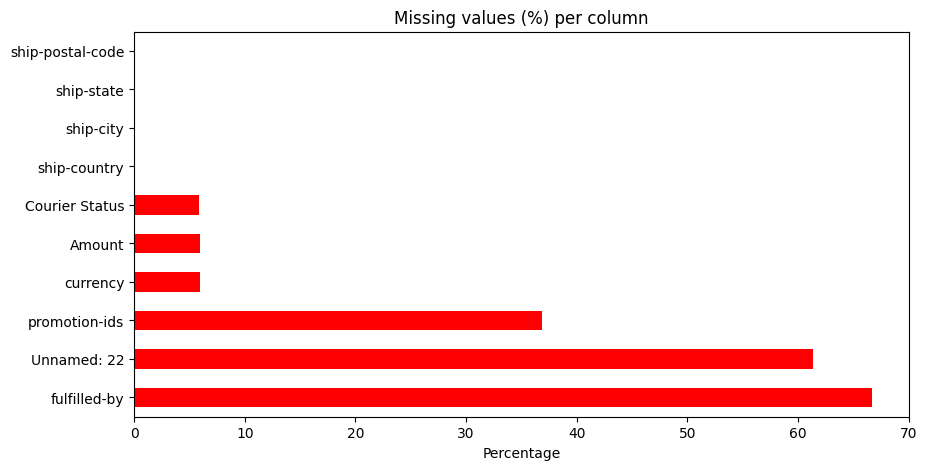

In [ ]:
# Missing values chart (only columns that have missing values)
m = missing[missing["missing_pct"] > 0]
if len(m) > 0:
    m["missing_pct"].plot(kind="barh", figsize=(10, 5), title="Missing values (%) per column", color="red")
    plt.xlabel("Percentage")
    plt.show()

2-Data Cleaning & Preprocessing

In [ ]:
#Clean column names (strip spaces and replace special characters with underscores)
E_Commerce.columns = [col.strip().replace(' ', '_').replace('-', '_') for col in E_Commerce.columns]


In [ ]:
#Drop unnecessary columns or those with extremely high missing rates
cols_to_drop = ['index', 'Unnamed:_22', 'fulfilled_by', 'promotion_ids']
E_Commerce.drop(columns=[col for col in cols_to_drop if col in E_Commerce.columns], inplace=True)

In [ ]:
#Handle missing values in 'Amount' using the median grouped by 'Category'
if 'Amount' in E_Commerce.columns and 'Category' in E_Commerce.columns:
    E_Commerce['Amount'] = E_Commerce['Amount'].fillna(E_Commerce.groupby('Category')['Amount'].transform('median'))
    E_Commerce['Amount'] = E_Commerce['Amount'].fillna(E_Commerce['Amount'].median())

In [ ]:
#Handle missing categorical values by filling with 'Unknown'
categorical_cols = ['Courier_Status', 'currency', 'ship_city', 'ship_state', 'ship_country']
for col in categorical_cols:
    if col in E_Commerce.columns:
        E_Commerce[col] = E_Commerce[col].fillna('Unknown')


In [ ]:
#Drop duplicate rows if any exist
duplicates_count = E_Commerce.duplicated().sum()
if duplicates_count > 0:
    E_Commerce.drop_duplicates(inplace=True)
    print(f"\nRemoved {duplicates_count} duplicate rows.")


Removed 3 duplicate rows.


In [ ]:
#Convert 'Date' column to proper datetime format
if 'Date' in E_Commerce.columns:
    E_Commerce['Date'] = pd.to_datetime(E_Commerce['Date'], errors='coerce')


print("Cleaned Dataset Shape:", E_Commerce.shape)

Cleaned Dataset Shape: (79948, 20)


/tmp/ipykernel_845/2163850851.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  E_Commerce['Date'] = pd.to_datetime(E_Commerce['Date'], errors='coerce')


Regression Model Building and Evaluation

In [ ]:
#variable and predictors
target = 'Amount'
predictors_cols = ['Qty', 'Category', 'Size', 'Fulfilment', 'Sales_Channel', 'Courier_Status']


In [ ]:
# Prepare feature matrix (X) and target vector (y)
X_raw = E_Commerce[predictors_cols].copy()
y = E_Commerce[target].copy()

In [ ]:
# One-Hot Encoding for categorical predictors (convert strings to binary dummy variables)
X = pd.get_dummies(X_raw, drop_first=True, dtype=int)
X

,Qty,Category_Bottom,Category_Ethnic Dress,Category_Saree,Category_Set,Category_Top,Category_Western Dress,Category_kurta,Size_4XL,Size_5XL,...,Size_M,Size_S,Size_XL,Size_XS,Size_XXL,Fulfilment_Merchant,Sales_Channel_Non-Amazon,Courier_Status_Shipped,Courier_Status_Unknown,Courier_Status_Unshipped
0,0,0,0,0,1,0,0,0,0,0,...,0,1,0,0,0,1,0,0,1,0
1,1,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,1,0,0
2,1,0,0,0,0,0,0,1,0,0,...,0,0,1,0,0,0,0,1,0,0
3,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
4,1,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79946,1,0,0,0,0,0,0,1,0,0,...,0,0,0,0,1,1,0,1,0,0
79947,1,0,0,0,1,0,0,0,0,0,...,0,0,0,1,0,1,0,1,0,0
79948,1,0,0,0,1,0,0,0,0,0,...,1,0,0,0,0,1,0,1,0,0
79949,1,0,0,0,1,0,0,0,0,0,...,1,0,0,0,0,0,0,1,0,0


In [ ]:
# Drop rows where the target 'y' has NaN values to ensure a clean model fit
valid_idx = y.dropna().index
X_clean = X.loc[valid_idx]
y_clean = y.loc[valid_idx]

# Split into training and testing using the cleaned data
train_X, test_X, train_y, test_y = train_test_split(X_clean, y_clean, test_size=0.4, random_state=42)

# Fit the Multiple Linear Regression Model
regression_model = LinearRegression()
regression_model.fit(train_X, train_y)

LinearRegression()

In [ ]:
# Make Predictions (Scoring) on both Training and Testing sets
train_pred = regression_model.predict(train_X)
test_pred = regression_model.predict(test_X)

In [ ]:
# Evaluate Model Performance using standard metrics (MAE, RMSE, R²)
# Training Set Evaluation
train_MAE = mean_absolute_error(train_y, train_pred)
train_RMSA = np.sqrt(mean_squared_error(train_y, train_pred))
train_r2 = r2_score(train_y, train_pred)

In [ ]:
#Testing/Holdout Set Evaluation
test_MAE = mean_absolute_error(test_y, test_pred)
test_RMSE = np.sqrt(mean_squared_error(test_y, test_pred))
test_r2 = r2_score(test_y, test_pred)

In [ ]:
train_MAE, train_RMSA, train_r2

(137.45671681245474, np.float64(202.7977373108909), 0.4501734714775064)

In [ ]:
test_MAE, test_RMSE, test_r2

(137.91232740058544, np.float64(203.33277495988565), 0.4470069184480935)

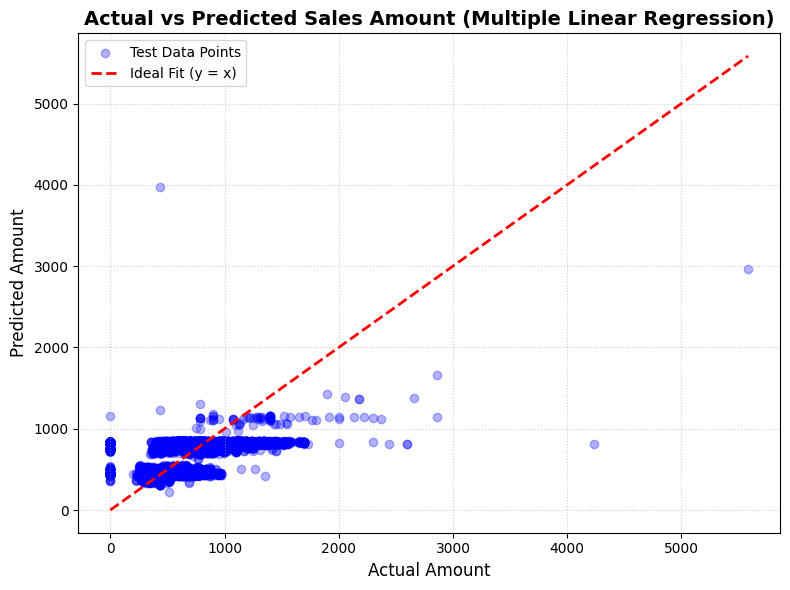

In [ ]:
#Actual vs Predicted scatter plot
plt.figure(figsize=(8, 6))

# Scatter plot of test actual values vs predicted values
plt.scatter(test_y, test_pred, alpha=0.3, color='blue', label='Test Data Points')

# Ideal fit line (y = x) representing 100% accurate prediction
min_val = min(test_y.min(), test_pred.min())
max_val = max(test_y.max(), test_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ideal Fit (y = x)')

# Graph titles and labels
plt.title('Actual vs Predicted Sales Amount (Multiple Linear Regression)', fontsize=14, fontweight='bold')
plt.xlabel('Actual Amount', fontsize=12)
plt.ylabel('Predicted Amount', fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

# Show plot
plt.tight_layout()
plt.show()

Random Forest Regressor

In [ ]:
# Initialize the Random Forest Regressor (setting random_state for reproducibility)
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

# Fit the model on the training data
rf.fit(train_X, train_y)

RandomForestRegressor(n_jobs=-1, random_state=42)

In [ ]:
# Generate predictions for both training and testing sets
rf_train_pred = rf.predict(train_X)
rf_test_pred = rf.predict(test_X)

In [ ]:
# Training Set Evaluation
rf_train_MAE = mean_absolute_error(train_y, rf_train_pred)
rf_train_RMSE = np.sqrt(mean_squared_error(train_y, rf_train_pred))
rf_train_r2 = r2_score(train_y, rf_train_pred)

# Testing/Holdout Set Evaluation
rf_test_MAE = mean_absolute_error(test_y, rf_test_pred)
rf_test_RMSE = np.sqrt(mean_squared_error(test_y, rf_test_pred))
rf_test_r2 = r2_score(test_y, rf_test_pred)

print(f"Train MAE: {rf_train_MAE:.4f}, RMSE: {rf_train_RMSE:.4f}, R²: {rf_train_r2:.4f}")
print(f"Test  MAE: {rf_test_MAE:.4f}, RMSE: {rf_test_RMSE:.4f}, R²: {rf_test_r2:.4f}")

Train MAE: 134.9388, RMSE: 198.8567, R²: 0.4713
Test  MAE: 136.2552, RMSE: 201.0801, R²: 0.4592


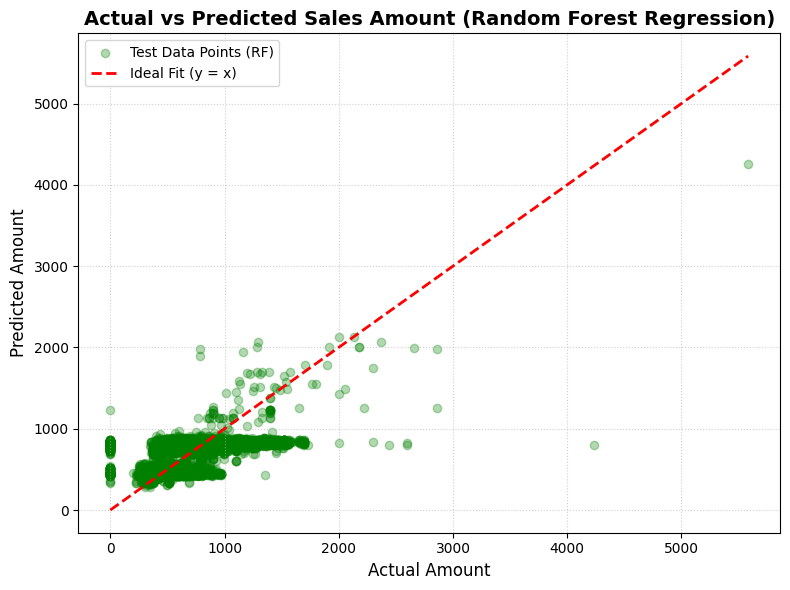

In [ ]:
plt.figure(figsize=(8, 6))

# Scatter plot of test actual values vs predicted values
plt.scatter(test_y, rf_test_pred, alpha=0.3, color='green', label='Test Data Points (RF)')

# Ideal fit line (y = x)
min_val = min(test_y.min(), rf_test_pred.min())
max_val = max(test_y.max(), rf_test_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ideal Fit (y = x)')

# Graph titles and labels
plt.title('Actual vs Predicted Sales Amount (Random Forest Regression)', fontsize=14, fontweight='bold')
plt.xlabel('Actual Amount', fontsize=12)
plt.ylabel('Predicted Amount', fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()